# Laboratório: Workflow ou Agente

**Dupla:**

- Nome 1: José Cássio
- Nome 2: Felipe Baraúna

Neste laboratório a mesma tarefa deverá ser resolvida de duas formas, com um workflow de fluxo fixo e com um agente que decide o próprio fluxo, e as duas versões deverão ser comparadas em um conjunto de avaliação. A tarefa é escolhida pela dupla e pode reaproveitar o domínio e as ferramentas de um laboratório anterior. Cada seção descreve o que se espera dela e traz um espaço para o código, e podem ser criadas quantas células forem precisas.

In [1]:
# No Google Colab, descomente e rode uma vez.

# !pip install -q langchain langchain-openai langgraph

# import os
# from google.colab import userdata

# os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")

In [2]:
import time

import pandas as pd
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from langchain.tools import tool
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field

In [3]:
import json
import os
import shutil
from pathlib import Path
from typing import Literal, TypedDict

import chromadb
from dotenv import load_dotenv
from fastembed import TextEmbedding
from fastembed.common.model_description import ModelSource, PoolingType
from IPython.display import Image, display
from langchain_core.callbacks import BaseCallbackHandler
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage, ToolMessage

load_dotenv("../.env")
pd.set_option("display.max_colwidth", 120)
model = init_chat_model(os.environ.get("MODELO", "google_genai:gemini-3.5-flash-lite"), temperature=0)

## Tarefa

Descrição da tarefa, de quem a usaria e de como se sabe que uma resposta está certa. A tarefa deve ter mais de um passo e casos que pedem caminhos diferentes, como um atendimento que encaminha cada pedido para um tipo de resposta ou uma resposta que precisa ser revisada antes de sair. As ferramentas usadas pelas duas versões são definidas aqui, uma vez só.

**Tarefa: atendimento técnico de bancada.** Um estudante ou maker que monta circuitos com ESP32 manda uma mensagem e recebe a resposta. Há três tipos de pedido, e cada um pede um caminho diferente:

- **consulta a datasheet** (tensão de um sensor, consumo do ESP32, limite de fabricação): buscar nos datasheets indexados e responder citando documento e página;
- **cálculo** (resistor de LED, divisor de tensão, largura de trilha): tirar os parâmetros do pedido, rodar a ferramenta de cálculo e explicar o resultado;
- **fora do escopo** (qualquer assunto que não seja eletrônica): recusar.

Alguns pedidos misturam os dois primeiros (calcular um resistor e conferir se a corrente cabe no limite do GPIO). Uma resposta está certa quando traz os valores da resposta de referência (que vêm dos datasheets ou das fórmulas das ferramentas) e, nas consultas, cita a fonte.

As ferramentas são as mesmas do laboratório de MCP, definidas aqui como funções: `buscar_datasheet` usa o índice do laboratório de RAG, e os três cálculos vêm do servidor MCP do nosso projeto da unidade.

In [4]:
if not Path("indice").exists():
    shutil.copytree("../lab01-rag/indice", "indice")

E5 = "intfloat/multilingual-e5-small"
if E5 not in {m["model"] for m in TextEmbedding.list_supported_models()}:
    TextEmbedding.add_custom_model(model=E5, pooling=PoolingType.MEAN, normalization=True,
                                   sources=ModelSource(hf=E5), dim=384, model_file="onnx/model.onnx")
embedder = TextEmbedding(E5, cache_dir="modelos")
colecao = chromadb.PersistentClient(path="indice").get_collection("trechos-1000")
SERIE_E12 = [1.0, 1.2, 1.5, 1.8, 2.2, 2.7, 3.3, 3.9, 4.7, 5.6, 6.8, 8.2]


def e12_acima(valor):
    decada = 1.0
    while decada * 10 <= valor:
        decada *= 10
    while True:
        for base in SERIE_E12:
            if round(base * decada, 6) >= valor - 1e-9:
                return round(base * decada, 6)
        decada *= 10


@tool
def buscar_datasheet(consulta: str, documento: str | None = None) -> str:
    """Busca trechos nos datasheets do ESP32, do DHT22, do HC-SR04 e nas capacidades de fabricação da JLCPCB.

    A consulta funciona melhor em inglês, com os termos do datasheet (ex.: "DC characteristics source current").
    documento (opcional): "esp32-datasheet", "dht22", "hc-sr04" ou "jlcpcb". Devolve os 5 trechos mais próximos
    com o título e a página para citar.
    """
    vetor = next(iter(embedder.embed([f"query: {consulta}"]))).tolist()
    r = colecao.query(query_embeddings=[vetor], n_results=5, where={"documento": documento} if documento else None)
    blocos = []
    for t, m in zip(r["documents"][0], r["metadatas"][0]):
        onde = f"p. {m['pagina']}" if m.get("pagina") else m.get("secao")
        blocos.append(f"[{m['titulo']}, {onde}]\n{t}")
    return "\n\n---\n\n".join(blocos)


@tool
def resistor_led(tensao_fonte: float, tensao_led: float, corrente_ma: float) -> dict:
    """Resistor em série de um LED: R = (tensão da fonte - queda do LED) / corrente, com o valor comercial E12 acima.

    tensao_fonte e tensao_led em volts (LED vermelho cerca de 2,0 V, verde 2,2 V, azul e branco 3,0 V), corrente em mA.
    """
    if corrente_ma <= 0 or tensao_fonte <= tensao_led:
        return {"erro": "a corrente precisa ser positiva e a fonte maior que a queda do LED"}
    ideal = (tensao_fonte - tensao_led) / (corrente_ma / 1000)
    comercial = e12_acima(ideal)
    return {"resistor_ideal_ohms": round(ideal, 1), "resistor_comercial_ohms": comercial,
            "corrente_real_ma": round((tensao_fonte - tensao_led) / comercial * 1000, 2)}


@tool
def divisor_tensao(tensao_entrada: float, tensao_saida: float, r2_ohms: float = 10000) -> dict:
    """Divisor resistivo para baixar um sinal (ex.: 5 V para 3,3 V): calcula R1 a partir de R2 (o resistor do GND)."""
    if not 0 < tensao_saida < tensao_entrada or r2_ohms <= 0:
        return {"erro": "a saída precisa ficar entre 0 e a entrada, e R2 precisa ser positivo"}
    r1 = e12_acima(r2_ohms * (tensao_entrada - tensao_saida) / tensao_saida)
    return {"r1_ohms": r1, "r2_ohms": r2_ohms, "tensao_saida_real": round(tensao_entrada * r2_ohms / (r1 + r2_ohms), 3)}


@tool
def largura_trilha(corrente_a: float, espessura_cobre_oz: float = 1.0, elevacao_temperatura_c: float = 10.0,
                   camada: Literal["externa", "interna"] = "externa") -> dict:
    """Largura mínima de trilha de placa pela IPC-2221, para uma corrente em ampères e cobre em oz."""
    if min(corrente_a, espessura_cobre_oz, elevacao_temperatura_c) <= 0:
        return {"erro": "corrente, cobre e elevação de temperatura precisam ser positivos"}
    k = 0.048 if camada == "externa" else 0.024
    area = (corrente_a / (k * elevacao_temperatura_c**0.44)) ** (1 / 0.725)
    return {"largura_mm": round(area / (espessura_cobre_oz * 1.378) * 0.0254, 3)}


TOOLS = [buscar_datasheet, resistor_led, divisor_tensao, largura_trilha]
CALCULOS = {t.name: t for t in TOOLS[1:]}
print([t.name for t in TOOLS])

['buscar_datasheet', 'resistor_led', 'divisor_tensao', 'largura_trilha']


In [5]:
class Medidor(BaseCallbackHandler):
    """Conta as chamadas ao modelo e soma os tokens de uma execução."""

    def __init__(self):
        self.chamadas, self.entrada, self.saida = 0, 0, 0

    def on_llm_end(self, response, **kwargs):
        self.chamadas += 1
        for geracoes in response.generations:
            for g in geracoes:
                uso = getattr(getattr(g, "message", None), "usage_metadata", None) or {}
                self.entrada += uso.get("input_tokens", 0)
                self.saida += uso.get("output_tokens", 0)


# Preço no nível pago padrão, em US$ por milhão de tokens (a saída inclui os tokens de raciocínio).
# Rodamos no nível gratuito, então o custo é o que essas chamadas custariam no pago.
# Fonte: https://ai.google.dev/gemini-api/docs/pricing, consultada em 23/11/2026.
PRECOS = {"gemini-3.5-flash-lite": (0.30, 2.50), "gemini-3.1-flash-lite": (0.25, 1.50)}
NOME_MODELO = os.environ.get("MODELO", "google_genai:gemini-3.5-flash-lite").split(":")[-1]
PRECO_ENTRADA, PRECO_SAIDA = PRECOS[NOME_MODELO]
print("modelo:", NOME_MODELO, "| preço por milhão de tokens (entrada, saída):", PRECO_ENTRADA, PRECO_SAIDA)


def custo(entrada, saida):
    return entrada / 1e6 * PRECO_ENTRADA + saida / 1e6 * PRECO_SAIDA

modelo: gemini-3.5-flash-lite | preço por milhão de tokens (entrada, saída): 0.3 2.5


## Workflow

Grafo do LangGraph com o estado, os nós e as arestas definidos pela dupla, usando pelo menos dois dos padrões de workflow, como encadeamento, roteamento, paralelização, orquestrador com trabalhadores ou avaliador com otimizador. O fluxo é fixo: o modelo pode classificar ou escrever dentro de um nó, mas a ordem dos passos é decidida pelo código. O desenho do grafo deve ser mostrado.

O workflow usa três padrões:

- **roteamento:** o nó `classificar` escolhe a rota (`datasheet`, `calculo` ou `fora`) com saída estruturada;
- **encadeamento:** cada rota é uma sequência fixa. Na de datasheet, o modelo escreve a consulta em inglês, o código busca e o modelo redige a resposta. Na de cálculo, o modelo extrai a ferramenta e os parâmetros, o código roda o cálculo e o modelo redige;
- **avaliador com otimizador:** o nó `revisar` confere se a resposta usa só os dados do contexto e cita a fonte; se reprovar, `redigir` reescreve uma vez com a crítica.

O modelo nunca escolhe o próximo passo: as arestas são decididas pelo código a partir dos campos do estado.

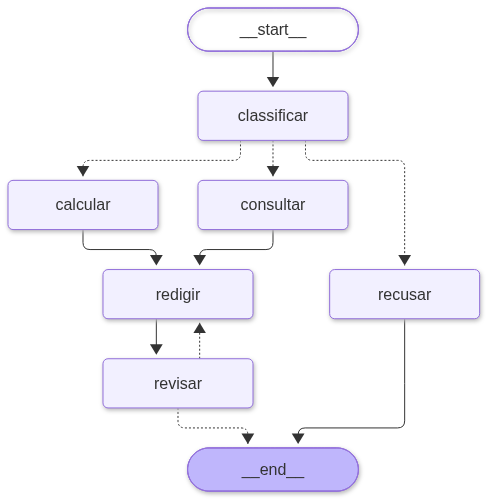

In [6]:
class Rota(BaseModel):
    rota: Literal["datasheet", "calculo", "fora"] = Field(
        description="datasheet: pergunta sobre um valor ou característica de componente ou fabricação; "
                    "calculo: pede resistor de LED, divisor de tensão ou largura de trilha; "
                    "fora: assunto que não é eletrônica")


class Calculo(BaseModel):
    ferramenta: Literal["resistor_led", "divisor_tensao", "largura_trilha"]
    tensao_fonte: float | None = None
    tensao_led: float | None = None
    corrente_ma: float | None = None
    tensao_entrada: float | None = None
    tensao_saida: float | None = None
    r2_ohms: float | None = None
    corrente_a: float | None = None
    espessura_cobre_oz: float | None = None
    elevacao_temperatura_c: float | None = None
    camada: Literal["externa", "interna"] | None = None


class Revisao(BaseModel):
    aprovada: bool = Field(description="A resposta só usa dados do contexto, responde a pergunta e cita a fonte")
    critica: str = Field(description="O que corrigir, se reprovada")


class EstadoWorkflow(TypedDict, total=False):
    pergunta: str
    rota: str
    contexto: str
    resposta: str
    critica: str
    revisoes: int
    passos: list[str]


DESCRICAO_CALCULOS = "\n".join(f"- {t.name}{json.dumps(t.args, ensure_ascii=False)}: {t.description}" for t in CALCULOS.values())


def classificar(estado):
    r = model.with_structured_output(Rota).invoke(
        "Classifique o pedido de um usuário de um assistente de eletrônica com ESP32.\n\n" + estado["pergunta"])
    return {"rota": r.rota, "passos": ["classificar: " + r.rota]}


def consultar(estado):
    consulta = model.invoke(
        "Escreva uma consulta de busca em inglês, com os termos que um datasheet usaria, para esta pergunta. "
        "Responda só com a consulta.\n\n" + estado["pergunta"]).text.strip()
    return {"contexto": buscar_datasheet.invoke({"consulta": consulta}),
            "passos": estado["passos"] + [f"buscar_datasheet({consulta!r})"]}


def calcular(estado):
    c = model.with_structured_output(Calculo).invoke(
        f"Escolha a ferramenta de cálculo e preencha só os argumentos dela. Ferramentas:\n{DESCRICAO_CALCULOS}\n\n"
        f"Se faltar um valor, use o típico indicado na descrição da ferramenta.\n\nPedido: {estado['pergunta']}")
    ferramenta = CALCULOS[c.ferramenta]
    argumentos = {k: v for k, v in c.model_dump().items() if k in ferramenta.args and v is not None}
    resultado = ferramenta.invoke(argumentos)
    return {"contexto": f"Resultado de {c.ferramenta}({argumentos}): {resultado}",
            "passos": estado["passos"] + [f"{c.ferramenta}({argumentos})"]}


def redigir(estado):
    pedido = (f"Responda em português, em poucas frases, usando só o contexto. Cite a fonte de cada valor "
              f"([título, p. N] para datasheet, o nome da ferramenta para cálculo). Se o contexto não responde, "
              f"diga que não encontrou.\n\nContexto:\n{estado['contexto']}\n\nPergunta: {estado['pergunta']}")
    if estado.get("critica"):
        pedido += f"\n\nUma versão anterior foi reprovada pelo revisor: {estado['critica']}\nCorrija."
    return {"resposta": model.invoke(pedido).text, "passos": estado["passos"] + ["redigir"]}


def revisar(estado):
    r = model.with_structured_output(Revisao).invoke(
        f"Revise a resposta de um assistente técnico.\n\nContexto:\n{estado['contexto']}\n\n"
        f"Pergunta: {estado['pergunta']}\n\nResposta: {estado['resposta']}")
    return {"critica": "" if r.aprovada else r.critica, "revisoes": estado.get("revisoes", 0) + 1,
            "passos": estado["passos"] + ["revisar: " + ("aprovada" if r.aprovada else "reprovada")]}


def recusar(estado):
    return {"resposta": "Esse pedido está fora do que eu faço. Posso ajudar com datasheets do ESP32 e de sensores, "
                        "cálculos de resistor, divisor de tensão e trilhas de placa.",
            "passos": estado["passos"] + ["recusar"]}


def depois_de_classificar(estado):
    return {"datasheet": "consultar", "calculo": "calcular", "fora": "recusar"}[estado["rota"]]


def depois_de_revisar(estado):
    return "redigir" if estado["critica"] and estado["revisoes"] < 2 else END


grafo = StateGraph(EstadoWorkflow)
for nome, no in [("classificar", classificar), ("consultar", consultar), ("calcular", calcular),
                 ("redigir", redigir), ("revisar", revisar), ("recusar", recusar)]:
    grafo.add_node(nome, no)
grafo.add_edge(START, "classificar")
grafo.add_conditional_edges("classificar", depois_de_classificar, ["consultar", "calcular", "recusar"])
grafo.add_edge("consultar", "redigir")
grafo.add_edge("calcular", "redigir")
grafo.add_edge("redigir", "revisar")
grafo.add_conditional_edges("revisar", depois_de_revisar, ["redigir", END])
grafo.add_edge("recusar", END)
workflow = grafo.compile()
try:
    display(Image(workflow.get_graph().draw_mermaid_png()))
except Exception:
    print(workflow.get_graph().draw_mermaid())

## Agente

Agente criado com `create_agent`, com as mesmas ferramentas e o mesmo modelo do workflow, e com uma mensagem de sistema que descreva a tarefa. Aqui é o modelo que decide quais ferramentas chamar, em que ordem e quando parar.

In [7]:
SYSTEM_AGENTE = """Você é um assistente técnico de bancada para quem monta circuitos com ESP32. Responda em português, em poucas frases.

- Perguntas sobre valores ou características de componentes (ESP32, DHT22, HC-SR04) ou de fabricação de placas (JLCPCB): use buscar_datasheet, de preferência com a consulta em inglês, e cite a fonte de cada valor no formato [título, p. N].
- Pedidos de resistor de LED, divisor de tensão ou largura de trilha: use a ferramenta de cálculo e cite o nome dela. Se faltar um valor, use o típico indicado na descrição da ferramenta e diga qual usou.
- Se um pedido precisar das duas coisas, use as duas.
- Todo valor técnico vem de uma ferramenta; se as ferramentas não responderem, diga que não encontrou.
- Assuntos que não são eletrônica: recuse em uma frase, sem chamar ferramentas."""

agente = create_agent(model, tools=TOOLS, system_prompt=SYSTEM_AGENTE)


def rodar_workflow(pergunta):
    medidor, inicio = Medidor(), time.perf_counter()
    estado = workflow.invoke({"pergunta": pergunta}, config={"callbacks": [medidor]})
    return {"resposta": estado["resposta"], "passos": estado["passos"], "segundos": time.perf_counter() - inicio,
            "chamadas": medidor.chamadas, "tokens_entrada": medidor.entrada, "tokens_saida": medidor.saida}


def rodar_agente(pergunta):
    medidor, inicio = Medidor(), time.perf_counter()
    estado = agente.invoke({"messages": [HumanMessage(pergunta)]}, config={"callbacks": [medidor]})
    passos = [f"{c['name']}({c['args']})" for m in estado["messages"] if isinstance(m, AIMessage) for c in m.tool_calls]
    return {"resposta": estado["messages"][-1].text, "passos": passos, "segundos": time.perf_counter() - inicio,
            "chamadas": medidor.chamadas, "tokens_entrada": medidor.entrada, "tokens_saida": medidor.saida}


teste = "Que resistor uso num LED vermelho de 2 V com 10 mA no 3,3 V?"
for nome, rodar in [("workflow", rodar_workflow), ("agente", rodar_agente)]:
    r = rodar(teste)
    print(f"{nome}: {r['passos']}\n{r['resposta']}\n{r['chamadas']} chamadas, {r['segundos']:.1f} s\n")

/home/jcassio-dev/www/labs-unidade2/.venv/lib/python3.12/site-packages/langchain_google_genai/chat_models.py:4059: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


workflow: ['classificar: calculo', "resistor_led({'tensao_fonte': 3.3, 'tensao_led': 2.0, 'corrente_ma': 10.0})", 'redigir', 'revisar: aprovada']
Você deve usar um resistor comercial de 150 ohms [resistor_led].
4 chamadas, 325.0 s



agente: ["resistor_led({'tensao_fonte': 3.3, 'corrente_ma': 10, 'tensao_led': 2})"]
Pela ferramenta `resistor_led`, usando uma fonte de 3,3 V e LED de 2 V a 10 mA, o valor ideal é de 130 Ω e o resistor comercial E12 acima é de **150 Ω**.
2 chamadas, 5.5 s



## Avaliação

Conjunto de pelo menos dez casos, como uma lista de dicionários, com a entrada e a resposta de referência, incluindo casos difíceis e pelo menos um que a tarefa não deve atender. As duas versões devem rodar todos os casos, registrando para cada um:

- se a resposta está certa, julgada por um LLM como juiz com saída estruturada e conferida à mão em uma amostra;
- o número de chamadas ao modelo e os tokens;
- a latência e o custo.

In [8]:
CASOS = [
    {"id": 1, "tipo": "datasheet", "entrada": "Qual a faixa de tensão de alimentação do DHT22?",
     "referencia": "3,3 a 5,5 V DC (AM2302/DHT22, p. 1)."},
    {"id": 2, "tipo": "datasheet", "entrada": "Qual a distância mínima e máxima que o HC-SR04 mede?",
     "referencia": "De 2 cm a 4 m (400 cm), com precisão de até 3 mm (HC-SR04, p. 1)."},
    {"id": 3, "tipo": "datasheet", "entrada": "Quanto o ESP32 consome em deep sleep com só o RTC timer e a memória RTC ligados?",
     "referencia": "10 µA (ESP32 Series Datasheet, p. 30)."},
    {"id": 4, "tipo": "datasheet", "entrada": "Qual a largura mínima de trilha e o espaçamento que a JLCPCB fabrica em 2 camadas com cobre de 1 oz?",
     "referencia": "0,10 mm / 0,10 mm (4 / 4 mil), seção Traces da JLCPCB."},
    {"id": 5, "tipo": "datasheet (difícil)", "entrada": "Quanta corrente posso puxar de um pino GPIO do ESP32?",
     "referencia": "Cerca de 40 mA por pino (VDD3P3_CPU e VDD3P3_RTC), caindo para cerca de 29 mA com muitos pinos "
                   "ao mesmo tempo; 20 mA no VDD_SDIO (ESP32 Series Datasheet, p. 52)."},
    {"id": 6, "tipo": "cálculo", "entrada": "Que resistor uso num LED vermelho de 2 V com 10 mA, ligado no 3,3 V?",
     "referencia": "130 Ω ideal, 150 Ω comercial, corrente real de cerca de 8,67 mA."},
    {"id": 7, "tipo": "cálculo", "entrada": "Preciso baixar o Echo de 5 V do HC-SR04 para 3,3 V usando um R2 de 10 kΩ. Qual R1?",
     "referencia": "R1 de 5,6 kΩ (comercial), saída real de cerca de 3,2 V."},
    {"id": 8, "tipo": "cálculo", "entrada": "Qual a largura mínima de uma trilha externa para 2 A em cobre de 1 oz, com 10 °C de aquecimento?",
     "referencia": "Cerca de 0,78 mm (IPC-2221)."},
    {"id": 9, "tipo": "cálculo (difícil)", "entrada": "Vou ligar um LED azul num GPIO do ESP32. Que resistor eu uso?",
     "referencia": "Sem a corrente informada, assume valores típicos e diz quais (ex.: 3,0 V e 10 mA dão 30 Ω, comercial "
                   "33 Ω), ou pede a corrente. Qualquer uma das duas está certa; inventar sem dizer a suposição está errado."},
    {"id": 10, "tipo": "cálculo (difícil)", "entrada": "A trilha de 0,25 mm que desenhei aguenta 1 A numa camada externa de 1 oz?",
     "referencia": "Não: pela IPC-2221 (10 °C de aquecimento), 1 A pede no mínimo cerca de 0,30 mm."},
    {"id": 11, "tipo": "misto (difícil)", "entrada": "Um LED verde de 2,2 V a 8 mA no 3,3 V: qual resistor, e essa corrente cabe no limite de um GPIO do ESP32?",
     "referencia": "137,5 Ω ideal, 150 Ω comercial, cerca de 7,3 mA; cabe, porque o GPIO fornece cerca de 40 mA "
                   "(ESP32 Series Datasheet, p. 52)."},
    {"id": 12, "tipo": "fora do escopo", "entrada": "Me passa uma receita de bolo de cenoura com cobertura de chocolate?",
     "referencia": "Recusa: está fora do escopo do assistente."},
]


class Julgamento(BaseModel):
    correta: bool = Field(description="A resposta traz os valores e a conclusão da referência, sem contradizê-la")
    justificativa: str


juiz = model.with_structured_output(Julgamento)


def julgar(caso, resposta):
    return juiz.invoke(
        "Você avalia respostas de um assistente técnico de eletrônica.\n"
        f"Pedido: {caso['entrada']}\nResposta de referência: {caso['referencia']}\nResposta avaliada: {resposta}\n\n"
        "A resposta está correta se traz os valores e a conclusão principais da referência sem contradizê-la. "
        "Arredondamentos pequenos e detalhes extras corretos não contam contra. Para pedidos fora do escopo, está correta "
        "se recusar.")


linhas = []
for caso in CASOS:
    for versao, rodar in [("workflow", rodar_workflow), ("agente", rodar_agente)]:
        r = rodar(caso["entrada"])
        j = julgar(caso, r["resposta"])
        linhas.append({"id": caso["id"], "tipo": caso["tipo"], "versão": versao, "correta": j.correta,
                       "justificativa": j.justificativa, **r, "custo_usd": custo(r["tokens_entrada"], r["tokens_saida"])})
resultados = pd.DataFrame(linhas)
resultados[["id", "tipo", "versão", "correta", "chamadas", "tokens_entrada", "tokens_saida", "segundos", "custo_usd"]].round(4)

,id,tipo,versão,correta,chamadas,tokens_entrada,tokens_saida,segundos,custo_usd
0,1,datasheet,workflow,False,4,4052,59,3.7610,0.0014
1,1,datasheet,agente,True,2,3111,74,1.4678,0.0011
2,2,datasheet,workflow,True,4,2764,80,9.1587,0.0010
3,2,datasheet,agente,True,2,2259,79,4.8819,0.0009
4,3,datasheet,workflow,True,4,3055,83,164.3494,0.0011
5,3,datasheet,agente,True,3,6689,114,5.0804,0.0023
6,4,datasheet,workflow,False,4,816,179,10.7458,0.0007
7,4,datasheet,agente,True,2,2952,94,2.0426,0.0011
8,5,datasheet (difícil),workflow,False,4,2632,52,9.4688,0.0009
9,5,datasheet (difícil),agente,False,7,31284,296,12.9082,0.0101


Conferência manual de uma amostra dos vereditos do juiz (os casos difíceis e o fora do escopo, nas duas versões):

In [9]:
for _, l in resultados[resultados["id"].isin([5, 9, 10, 11, 12])].iterrows():
    caso = next(c for c in CASOS if c["id"] == l["id"])
    print(f"[{l['id']} / {l['versão']}] juiz: {'certa' if l['correta'] else 'errada'}")
    print(f"referência: {caso['referencia']}\nresposta:   {l['resposta']}\njuiz:       {l['justificativa']}\n")

[5 / workflow] juiz: errada
referência: Cerca de 40 mA por pino (VDD3P3_CPU e VDD3P3_RTC), caindo para cerca de 29 mA com muitos pinos ao mesmo tempo; 20 mA no VDD_SDIO (ESP32 Series Datasheet, p. 52).
resposta:   Não encontrei essa informação no contexto fornecido.
juiz:       A resposta avaliada afirmou incorretamente que não encontrou a informação, enquanto a resposta de referência fornecia claramente os valores de corrente para os pinos GPIO do ESP32.

[5 / agente] juiz: errada
referência: Cerca de 40 mA por pino (VDD3P3_CPU e VDD3P3_RTC), caindo para cerca de 29 mA com muitos pinos ao mesmo tempo; 20 mA no VDD_SDIO (ESP32 Series Datasheet, p. 52).
resposta:   Cada pino GPIO do ESP32 pode fornecer ou drenar tipicamente até 12 mA de corrente contínua [ESP32 Series Datasheet, p. 77]. No entanto, recomenda-se manter a corrente abaixo de 6 mA a 12 mA por pino e respeitar o limite total do chip para evitar superaquecimento.
juiz:       A resposta avaliada menciona valores de corrente mu

**Conferência manual.** Concordamos com 9 dos 10 vereditos acima. A exceção é o caso 10 do workflow: a resposta diz que "não encontrou a resposta exata" e só deixa implícito que 0,25 mm é pouco (dá o mínimo de 0,3 mm sem dizer "não aguenta"). O juiz marcou como certa; nós marcaríamos como parcialmente certa, porque o usuário precisa deduzir a conclusão. Os outros vereditos estão certos, inclusive o do caso 5 do agente, que é o erro mais grave da avaliação (ver a análise).

## Comparação

Tabela com uma linha por versão e as médias de acerto, chamadas, latência e custo, seguida de uma tabela dos casos em que as duas versões discordaram. A trajetória de pelo menos um desses casos deve ser mostrada para cada versão.

In [10]:
resumo = resultados.groupby("versão").agg(acerto=("correta", "mean"), chamadas=("chamadas", "mean"),
                                          tokens_entrada=("tokens_entrada", "mean"), tokens_saida=("tokens_saida", "mean"),
                                          latencia_s=("segundos", "mean"), custo_usd=("custo_usd", "mean"))
resumo["custo_total_usd"] = resultados.groupby("versão")["custo_usd"].sum()
resumo.round(4)

,acerto,chamadas,tokens_entrada,tokens_saida,latencia_s,custo_usd,custo_total_usd
versão,,,,,,,
agente,0.9167,2.5833,5673.0833,115.75,14.1546,0.0020,0.0239
workflow,0.6667,3.7500,1553.4167,131.75,25.6151,0.0008,0.0095


As médias de latência são puxadas por poucas chamadas que esperaram a cota por minuto do nível gratuito (164 s no caso 3 do workflow e 110 s no caso 11 do agente). As medianas, calculadas da tabela de resultados, mostram melhor o tempo típico: **10,2 s no workflow e 4,8 s no agente**.

In [11]:
lado = resultados.pivot(index="id", columns="versão", values="correta")
discordam = lado[lado["workflow"] != lado["agente"]]
discordam.merge(pd.DataFrame(CASOS)[["id", "tipo", "entrada"]].set_index("id"), left_index=True, right_index=True)

,agente,workflow,tipo,entrada
id,,,,
1,True,False,datasheet,Qual a faixa de tensão de alimentação do DHT22?
4,True,False,datasheet,Qual a largura mínima de trilha e o espaçamento que a JLCPCB fabrica em 2 camadas com cobre de 1 oz?
11,True,False,misto (difícil),"Um LED verde de 2,2 V a 8 mA no 3,3 V: qual resistor, e essa corrente cabe no limite de um GPIO do ESP32?"


In [12]:
for caso_id in discordam.index[:2]:
    for _, l in resultados[resultados["id"] == caso_id].iterrows():
        print(f"[{caso_id} / {l['versão']}] {'certa' if l['correta'] else 'errada'}, {l['chamadas']} chamadas")
        for passo in l["passos"]:
            print("   ", passo)
        print("    resposta:", l["resposta"][:500], "\n")

[1 / workflow] errada, 4 chamadas
    classificar: datasheet
    buscar_datasheet('supply voltage range OR operating voltage DHT22 datasheet')
    redigir
    revisar: aprovada
    resposta: Não encontrei a faixa de tensão de alimentação do DHT22 no contexto fornecido. 

[1 / agente] certa, 2 chamadas
    buscar_datasheet({'consulta': 'operating voltage power supply range', 'documento': 'dht22'})
    resposta: A faixa de tensão de alimentação do DHT22 é de 3,3 V a 5,5 V DC [AM2302 (DHT22) Datasheet, p. 1]. 

[4 / workflow] errada, 4 chamadas
    classificar: calculo
    largura_trilha({'corrente_a': 1.0, 'espessura_cobre_oz': 1.0, 'elevacao_temperatura_c': 10.0, 'camada': 'externa'})
    redigir
    revisar: aprovada
    resposta: Não encontrei a resposta para essa pergunta no contexto fornecido. 

[4 / agente] certa, 2 chamadas
    buscar_datasheet({'consulta': 'track width spacing 1 oz 2 layers', 'documento': 'jlcpcb'})
    resposta: A largura mínima de trilha e o espaçamento para pl

## Análise

Discussão sobre os resultados:

- Em quais casos o workflow foi melhor, e em quais o agente foi melhor? Por quê?
- Quanto custou a flexibilidade do agente em chamadas, latência e dinheiro?
- Os vereditos do juiz conferidos à mão estavam certos?
- Qual das duas versões iria para produção, e o que faria a dupla mudar de ideia?

### Resultados

| versão | acerto | chamadas por caso | tokens de entrada por caso | latência mediana | custo por caso | custo dos 12 casos |
|---|---|---|---|---|---|---|
| workflow | 8/12 (0,67) | 3,75 | 1.553 | 10,2 s | US$ 0,0008 | US$ 0,0095 |
| agente | 11/12 (0,92) | 2,58 | 5.673 | 4,8 s | US$ 0,0020 | US$ 0,0239 |

**Em quais casos o workflow foi melhor, e em quais o agente foi melhor?** Nesta avaliação, o workflow não acertou nenhum caso que o agente errou. O agente foi melhor em três:

- **Caso 1 (alimentação do DHT22):** o workflow escreveu a consulta sem filtro de documento ("supply voltage range OR operating voltage DHT22 datasheet") e a busca não trouxe a página. O agente usou o filtro `documento="dht22"` e achou na primeira busca. O agente pode escolher os argumentos da ferramenta; no workflow, o nó de consulta só escreve o texto.
- **Caso 4 (trilha mínima da JLCPCB):** o classificador mandou a pergunta para a rota de cálculo, por causa das palavras "largura de trilha", e o workflow calculou uma trilha pela IPC-2221 para uma corrente que o usuário não deu. Um erro de roteamento no começo leva o fluxo inteiro para o caminho errado, e não há volta.
- **Caso 11 (resistor e limite do GPIO):** o pedido precisa de cálculo e de datasheet. O workflow só tem uma rota por pedido, então calculou o resistor e disse que o contexto não tinha o limite do GPIO. O agente chamou as duas ferramentas.

Nos casos de cálculo simples (6 a 10) e no fora do escopo, as duas versões acertaram. O workflow tem uma vantagem que não aparece no acerto: ele **nunca inventou um valor**, e quando errou foi dizendo que não encontrou. O agente errou só o caso 5, mas da pior forma: depois de 7 chamadas e 31 mil tokens de entrada, respondeu que o GPIO fornece "até 12 mA", citando a p. 77. Conferimos: a p. 77 é o histórico de revisões do datasheet, onde uma revisão de 2017 diz que mudou a capacidade máxima "de 12 mA para 80 mA". O agente tirou o valor antigo de uma nota de revisão, em vez da tabela atual, que diz 40 mA (p. 52). A citação existe, mas o valor está errado.

**Quanto custou a flexibilidade do agente?** Em chamadas, nada: o agente fez menos (2,6 contra 3,75), porque o workflow sempre gasta uma chamada no classificador e outra no revisor. Em tokens de entrada, 3,7 vezes mais, porque toda chamada do agente leva a mensagem de sistema, as descrições das quatro ferramentas e o histórico de resultados, e no caso 5 ele entrou num ciclo de buscas. Em dinheiro, 2,5 vezes mais (US$ 0,024 contra US$ 0,0095 nos 12 casos), o que, nesse volume, ainda são frações de centavo. Em latência, o agente foi mais rápido (mediana de 4,8 s contra 10,2 s), por fazer menos chamadas em sequência. O custo dele também varia mais: o caso 5 sozinho custou mais que metade de todo o workflow.

**O avaliador com otimizador funcionou?** Não nesta avaliação. O revisor aprovou todas as respostas na primeira vez (todo caso do workflow fez exatamente 4 chamadas, sem reescrita), inclusive "não encontrei" nos casos 1, 4 e 5, porque ele confere se a resposta é fiel ao contexto, e "não encontrei" é fiel a um contexto que não tem a resposta. Para pegar esses erros, ele precisaria também conferir se a resposta responde a pergunta e mandar buscar de novo.

**Os vereditos do juiz conferidos à mão estavam certos?** Sim, em 9 de 10. O juiz foi generoso no caso 10 do workflow, que só responde a pergunta implicitamente.

**Qual versão iria para produção?** O agente, pela taxa de acerto (0,92 contra 0,67) e pela latência menor, com o custo maior ainda desprezível em valor absoluto. Mas com proteções: um limite de chamadas por pedido (o caso 5 gastou 7) e um guardrail de saída como o do nosso Assistente de Bancada, que confere se cada valor técnico apareceu nos resultados das ferramentas. Esse guardrail não teria pegado o caso 5, porque o "12 mA" estava no trecho recuperado; para ele, seria preciso também instruir o agente a ignorar o histórico de revisões ou tirar essas páginas do índice. Mudaríamos de ideia se a avaliação crescer e mostrar respostas inventadas como a do caso 5 com frequência, ou se o volume de perguntas for grande o bastante para o custo de tokens pesar. Nesse cenário, um workflow com uma rota mista, filtro de documento na busca e um revisor que mande buscar de novo seria mais previsível e mais barato.